In [1]:
import pandas as pd, numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

RAW = Path("../data/raw")
archivos = sorted(RAW.glob("*.parquet"))
print(len(archivos), "curvas disponibles")

det = pd.read_parquet(archivos[0])
print(archivos[0].stem)
print(det["fid"].value_counts())
print(det["isdiffpos"].value_counts())
det.head()

5356 curvas disponibles
ZTF17aabtvsy
fid
2    13
1    10
Name: count, dtype: int64
isdiffpos
 1    22
-1     1
Name: count, dtype: int64


,mjd,fid,magpsf,sigmapsf,ra,dec,isdiffpos
0,59850.515694,2,17.598600,0.169676,158.883533,37.649503,-1
1,59850.518275,2,18.264800,0.192368,158.883781,37.649599,1
2,59864.474641,1,18.349186,0.130138,158.883618,37.649683,1
3,59864.487257,2,18.296770,0.114468,158.883912,37.649755,1
4,59866.467500,1,18.237980,0.099298,158.883662,37.649687,1


In [2]:
ZP = 26.3

def a_flujo(det):
    det = det[det["fid"].isin([1, 2])].copy()           # solo bandas g y r
    det = det[det["isdiffpos"] == 1]                    # descartar diferencias negativas
    det["banda"] = det["fid"].map({1: "g", 2: "r"})
    det["flujo"] = 10 ** (-0.4 * (det["magpsf"] - ZP))
    det["flujo_err"] = 0.4 * np.log(10) * det["flujo"] * det["sigmapsf"]
    return det.sort_values("mjd").reset_index(drop=True)

In [3]:
curva = a_flujo(det)
print(len(det), "->", len(curva))
print(curva[["mjd", "banda", "magpsf", "flujo", "flujo_err"]].head())

23 -> 22
            mjd banda     magpsf        flujo   flujo_err
0  59850.518275     r  18.264800  1637.118062  290.060446
1  59864.474641     g  18.349186  1514.696424  181.553269
2  59864.487257     r  18.296770  1589.615175  167.591790
3  59866.467500     g  18.237980  1678.061989  153.469965
4  59866.503380     r  18.188007  1757.102918  142.827847


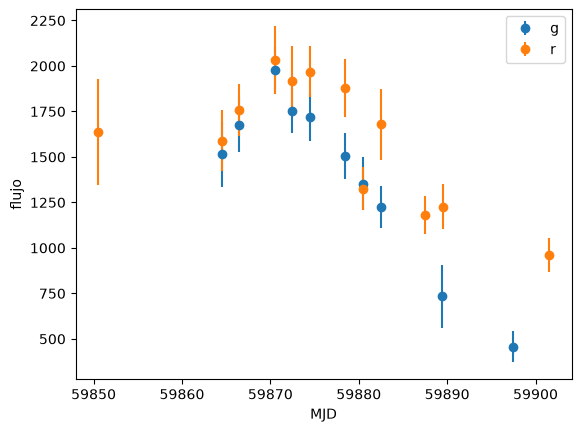

In [4]:
for b, c in curva.groupby("banda"):
    plt.errorbar(c["mjd"], c["flujo"], yerr=c["flujo_err"], fmt="o", label=b)
plt.xlabel("MJD"); plt.ylabel("flujo"); plt.legend(); plt.show()

**Recorte de Cola:** Calcula la pendiente maxima buscando la recta que une el punto de mayor flujo con el último punto.
Recorre los puntos posteriores al máximo y busca el primero cuya pendiente hasta el último punto sea menor que 0,2 veces la pendiente máxima. Eso indica que desde ahí el flujo está casi plano.
Elimina todo lo que viene después de ese punto.

En el paper no estas detallado como es este algoritmo, asi que esta reconstruido mediante su descripcion.

In [11]:
def recorta_cola(c):
    """c: puntos de UNA banda, ordenados por mjd."""
    if len(c) < 3:
        return c
    t, f = c["mjd"].to_numpy(), c["flujo"].to_numpy()
    ip = f.argmax()
    if ip >= len(c) - 1:
        return c
    dt = t[-1] - t[ip]
    if dt <= 0:                      # el último punto coincide en tiempo con el máximo
        return c
    pend_max = abs(f[-1] - f[ip]) / dt
    for i in range(ip + 1, len(c) - 1):
        if t[-1] == t[i]:
            continue
        pend = abs(f[-1] - f[i]) / (t[-1] - t[i])
        if pend < 0.2 * pend_max:
            return c.iloc[: i + 1]
    return c

**Cortes de calidad**:
Al menos 5 puntos con SNR ≥ 3, donde SNR = flujo / error.
La amplitud no puede ser menor que 3 veces el error medio.
La desviación estándar del flujo no puede ser menor que el error medio.

In [6]:
def procesa(det):
    """Devuelve (curva_limpia, None) si pasa, o (None, motivo) si no."""
    curva = a_flujo(det)
    bandas = {}
    for b in ["g", "r"]:
        c = curva[curva["banda"] == b]
        if len(c) == 0:
            return None, f"sin puntos en {b}"
        bandas[b] = recorta_cola(c)
    for b, c in bandas.items():
        snr = c["flujo"] / c["flujo_err"]
        if (snr >= 3).sum() < 5:
            return None, f"menos de 5 puntos con SNR>=3 en {b}"
        err = c["flujo_err"].mean()
        if c["flujo"].max() - c["flujo"].min() < 3 * err:
            return None, f"amplitud baja en {b}"
        if c["flujo"].std() < err:
            return None, f"variabilidad baja en {b}"
    return pd.concat(bandas.values()).sort_values("mjd").reset_index(drop=True), None

In [7]:
import random
from collections import Counter

random.seed(0)
prueba = random.sample(archivos, 100)
pasan, motivos = 0, Counter()
for a in prueba:
    _, motivo = procesa(pd.read_parquet(a))
    if motivo is None:
        pasan += 1
    else:
        motivos[motivo] += 1

print("pasan:", pasan, "de", len(prueba))
print(motivos.most_common())

pasan: 99 de 100
[('variabilidad baja en r', 1)]


In [8]:
quitados = []
for a in prueba:
    curva = a_flujo(pd.read_parquet(a))
    q = 0
    for b in ["g", "r"]:
        c = curva[curva["banda"] == b]
        q += len(c) - len(recorta_cola(c))
    quitados.append(q)

recortadas = [q for q in quitados if q > 0]
print("curvas con al menos un punto recortado:", len(recortadas), "de", len(prueba))
print("mediana de puntos quitados (entre las recortadas):", np.median(recortadas))

curvas con al menos un punto recortado: 53 de 100
mediana de puntos quitados (entre las recortadas): 3.0


ZTF21abglcxm variabilidad baja en r


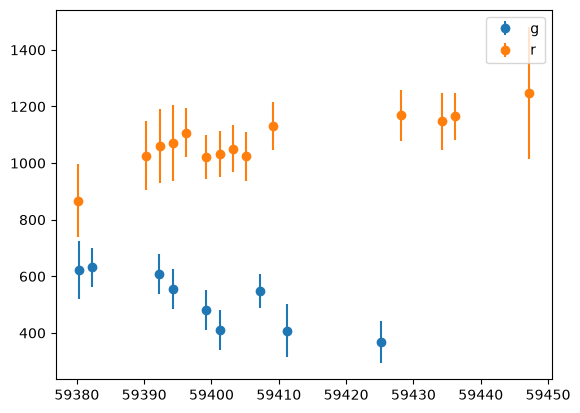

In [9]:
for a in prueba:
    _, motivo = procesa(pd.read_parquet(a))
    if motivo is not None:
        print(a.stem, motivo)
        curva = a_flujo(pd.read_parquet(a))
        for b, c in curva.groupby("banda"):
            plt.errorbar(c["mjd"], c["flujo"], yerr=c["flujo_err"], fmt="o", label=b)
        plt.legend(); plt.show()
        break

**5356 curvas descargadas:** Se realiza el procesamiento de datos para limpiarlos y quedarnos con los datos de mayor calidad.

In [12]:
muestra = pd.read_csv("../data/muestra.csv")
PROC = Path("../data/processed"); PROC.mkdir(exist_ok=True)

filas = []
for a in sorted(RAW.glob("*.parquet")):
    curva, motivo = procesa(pd.read_parquet(a))
    if curva is not None:
        curva.to_parquet(PROC / a.name, index=False)
    filas.append({"NAME": a.stem, "pasa": motivo is None, "motivo": motivo})

res = pd.DataFrame(filas).merge(muestra, on="NAME")
res.to_csv("../data/resultado_cortes.csv", index=False)

tabla = res.groupby("CLASE")["pasa"].agg(n="size", pasan="sum", frac_pasa="mean")
tabla["frac_eliminada"] = 1 - tabla["frac_pasa"]
print(tabla.round(3))
print(res["motivo"].value_counts())
print("total que pasa:", res["pasa"].sum(), "de", len(res))

            n  pasan  frac_pasa  frac_eliminada
CLASE                                          
SLSN-I     79     71      0.899           0.101
SN II     868    838      0.965           0.035
SN IIn    212    204      0.962           0.038
SN Ia    3979   3898      0.980           0.020
SN Ib/c   218    213      0.977           0.023
motivo
sin puntos en g                      66
variabilidad baja en r               16
menos de 5 puntos con SNR>=3 en r    15
sin puntos en r                      12
menos de 5 puntos con SNR>=3 en g    11
variabilidad baja en g                8
amplitud baja en r                    2
amplitud baja en g                    2
Name: count, dtype: int64
total que pasa: 5224 de 5356


En comparacion con el paper, la fraccion eliminada es mucho menor, es decir, hay muchos más datos que pasaron el control de calidad. Puede ser que el traning_set.csv tenga la informacion de los objetos con mejores curvas. O tambien podria suceder que las curvas ahora poseen mayor calidad, debido ha que ellos obtuvieron datos hasta octubre de 2023.

In [13]:
sin_g = res[res["motivo"] == "sin puntos en g"]["NAME"]
for nombre in sin_g.head(10):
    raw = pd.read_parquet(RAW / f"{nombre}.parquet")
    print(nombre, raw.groupby(["fid", "isdiffpos"]).size().to_dict())

ZTF18aaayemw {(1, -1): 343, (2, -1): 449}
ZTF18aabssth {(1, -1): 136, (2, -1): 481, (3, -1): 68}
ZTF18aabstmw {(1, -1): 198, (2, -1): 950}
ZTF18aaccuih {(1, -1): 243, (2, -1): 390}
ZTF18aagrdcs {(1, -1): 419, (2, 1): 26}
ZTF18aagrtxs {(1, -1): 437, (2, 1): 16}
ZTF18aagstdc {(1, -1): 554, (2, -1): 523, (3, -1): 1}
ZTF18aagtcxj {(1, -1): 1061, (2, -1): 1104}
ZTF18aagtdce {(1, -1): 1134, (2, -1): 1177}
ZTF18aahfzea {(1, -1): 255, (2, 1): 14}


In [14]:
perdidos = res[res["motivo"].fillna("").str.startswith("sin puntos")]
print(perdidos["CLASE"].value_counts())
print(perdidos["NAME"].str[:5].value_counts())  

CLASE
SN Ia      55
SN II      13
SN Ib/c     4
SN IIn      3
SLSN-I      3
Name: count, dtype: int64
NAME
ZTF18    78
Name: count, dtype: int64


Se eliminaron los objetos con diferencias negativas, todas son del año 2018. Son solo 78 curvas, no puedo asegurar si son objetos con poco brillo o es que ya brillaban más antes de empezar a ser observadas.